In [1]:
import cv2 
import numpy as np
import os 
import matplotlib.pyplot as plt

def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        img = cv2.imread(os.path.join(folder, filename))
        if img is not None:
            images.append(img)
    return images

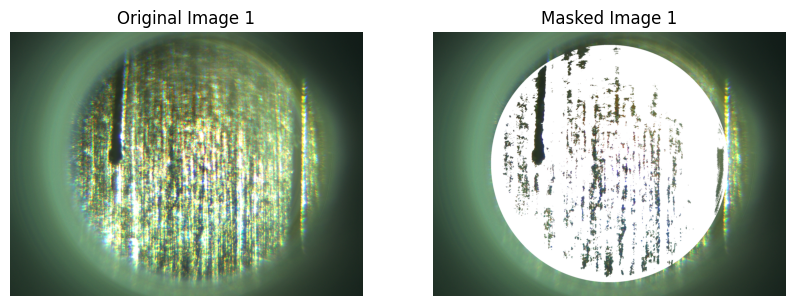

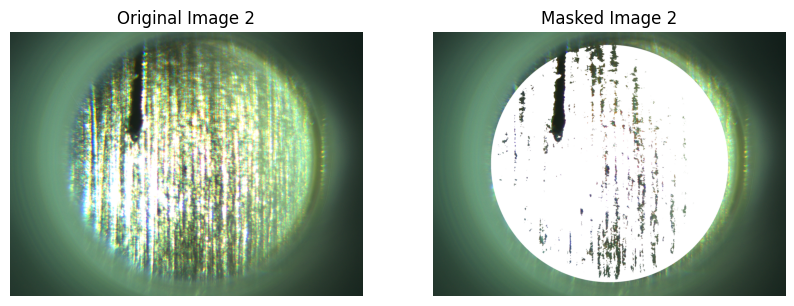

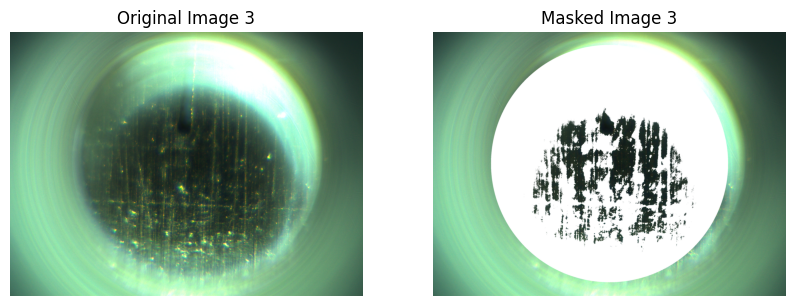

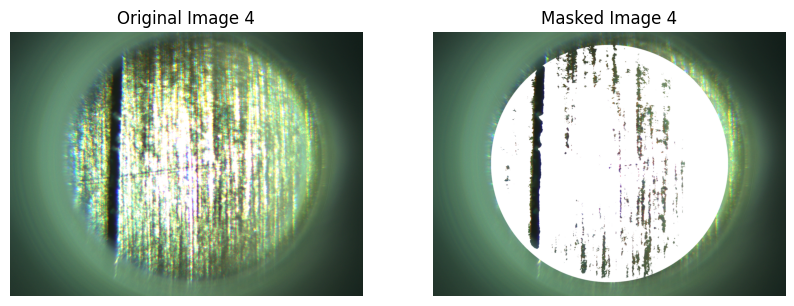

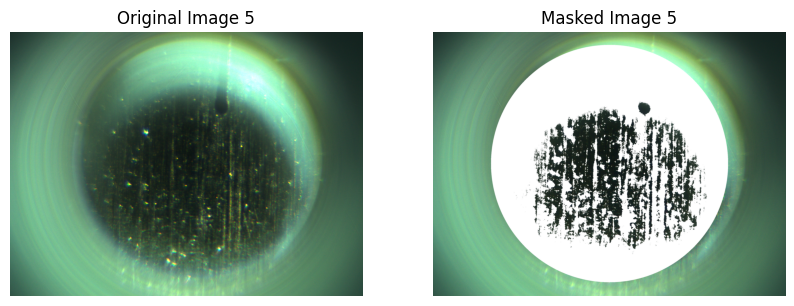

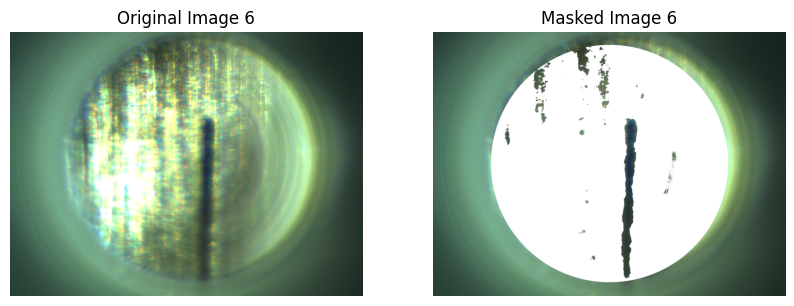

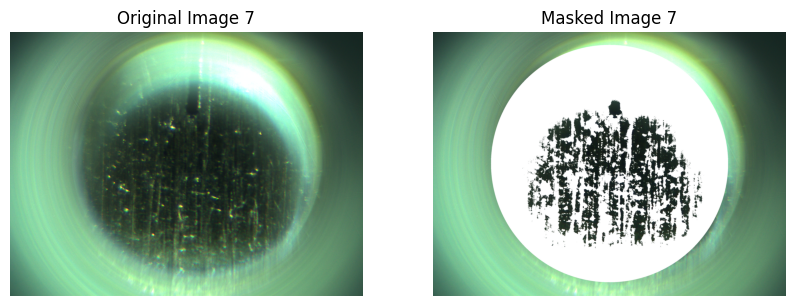

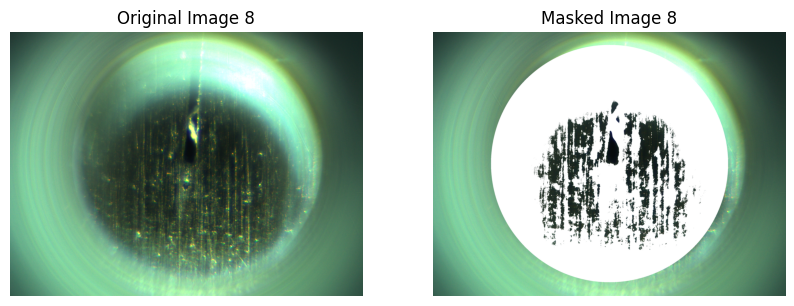

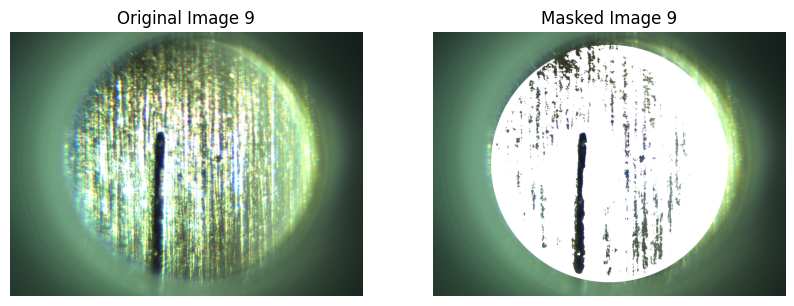

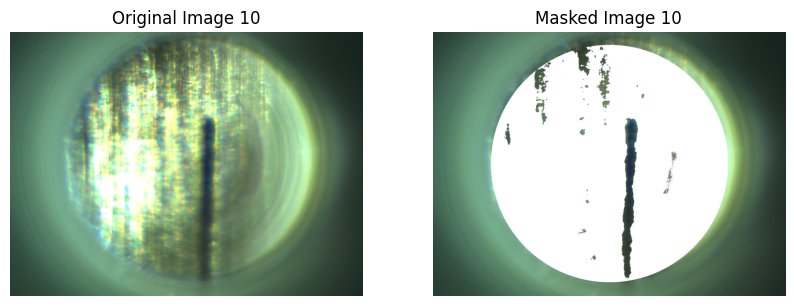

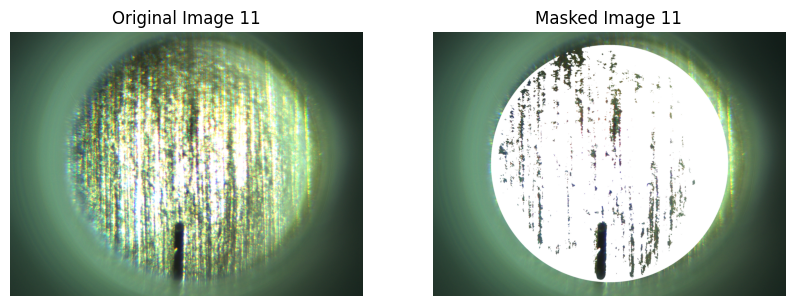

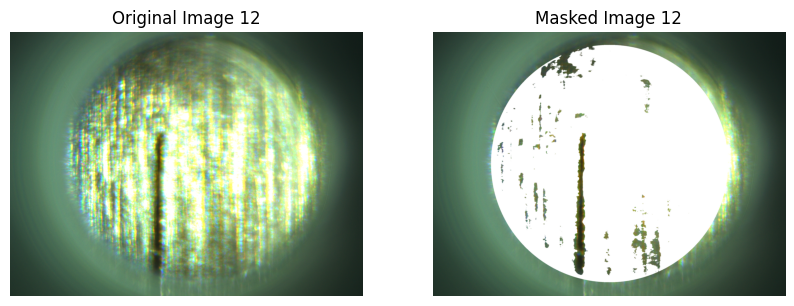

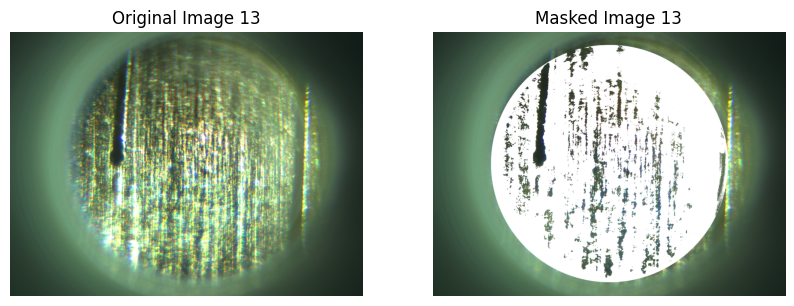

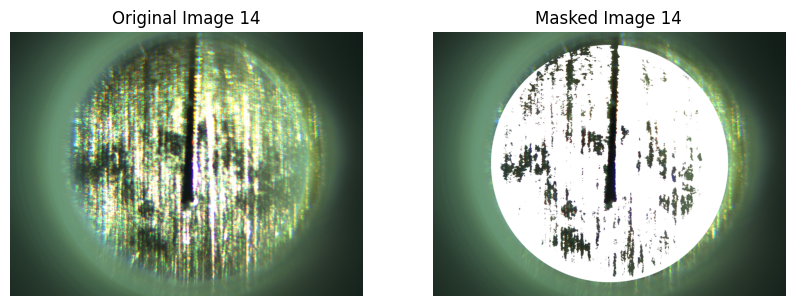

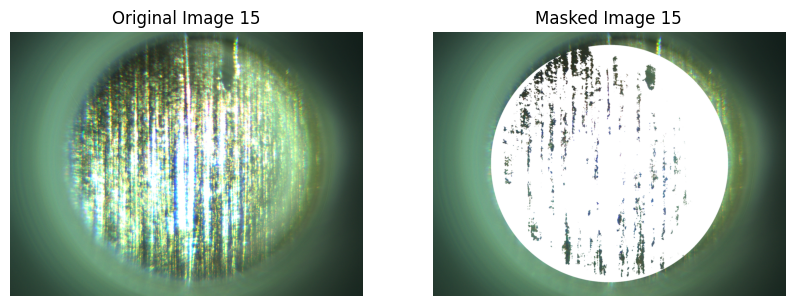

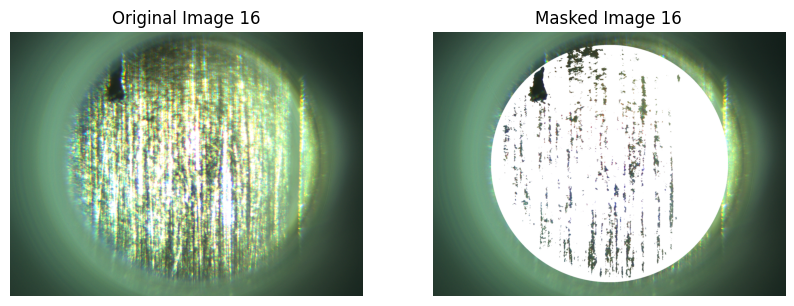

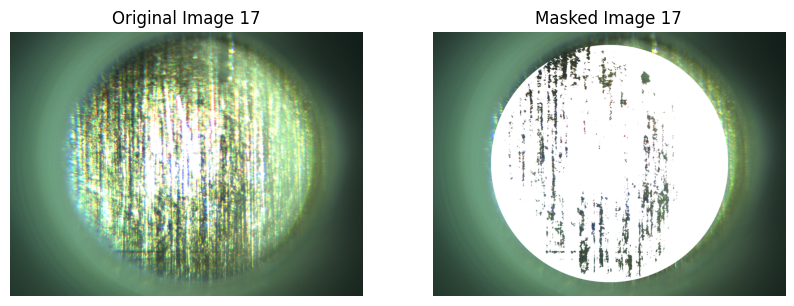

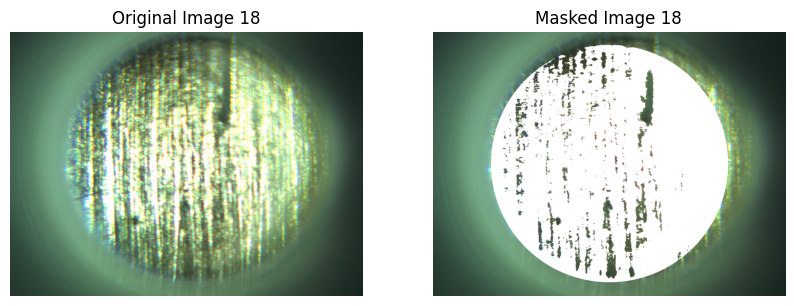

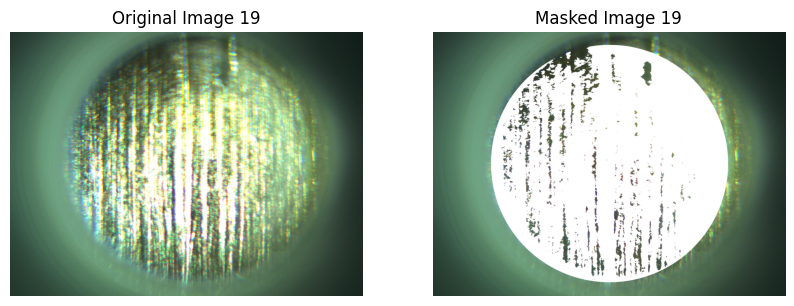

In [31]:
folder = "images/horizontal"
images = load_images_from_folder(folder)

for i, img in enumerate(images):
    img_cv = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    # crop the circular roi in the center of the image  
    radius = min(img_cv.shape[0], img_cv.shape[1]) // 2 - 100
    center = (img_cv.shape[1] // 2, img_cv.shape[0] // 2)
    mask = np.zeros(img_cv.shape[:2], dtype=np.uint8)
    cv2.circle(mask, center, radius, 255, -1)   
    img = cv2.bitwise_and(img_cv, img_cv, mask=mask)

    # perform clahe on the cropped image to enhance contrast
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    # thresholding to only keep colors that are close to black
    black_thresh = 55  # Adjust this threshold value as needed
    _, thresh = cv2.threshold(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), black_thresh, 255, cv2.THRESH_BINARY_INV)
    # create a mask for black pixels
    mask = cv2.bitwise_and(img_cv, img_cv, mask=thresh)
    # set non-black pixels to white
    mask[thresh == 0] = [255, 255, 255]
    # show original and masked images side by side
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_cv)
    plt.title(f'Original Image {i+1}')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(mask)
    plt.title(f'Masked Image {i+1}')
    plt.axis('off')
    plt.show()